## Homework 4: Hear Disease Classification

##### Pre-Processing

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

In [36]:
#load data
df = pd.read_csv("heart.csv", encoding="utf-8-sig")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [37]:
# Missing values: none are NaN, but thal = 0 and ca = 4 are invalid codes
print(df.isnull().sum().sum())
print((df["thal"] == 0).sum(), (df["ca"] == 4).sum())

# Replace invalid codes with the most common value (mode)
df.loc[df["thal"] == 0, "thal"] = df["thal"].mode()[0]
df.loc[df["ca"] == 4, "ca"] = df["ca"].mode()[0]

# Drop duplicate rows
df = df.drop_duplicates()
df.shape

0
2 5


(302, 14)

In [38]:
#descriptive stats on cleaned data
df.describe().round(2)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00
mean,54.42,0.68,0.96,131.60,246.50,0.15,0.53,149.57,0.33,1.04,1.40,0.67,2.33,0.54
std,9.05,0.47,1.03,17.56,51.75,0.36,0.53,22.90,0.47,1.16,0.62,0.94,0.58,0.50
min,29.00,0.00,0.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,0.00,0.00,1.00,0.00
25%,48.00,0.00,0.00,120.00,211.00,0.00,0.00,133.25,0.00,0.00,1.00,0.00,2.00,0.00
50%,55.50,1.00,1.00,130.00,240.50,0.00,1.00,152.50,0.00,0.80,1.00,0.00,2.00,1.00
75%,61.00,1.00,2.00,140.00,274.75,0.00,1.00,166.00,1.00,1.60,2.00,1.00,3.00,1.00
max,77.00,1.00,3.00,200.00,564.00,1.00,2.00,202.00,1.00,6.20,2.00,3.00,3.00,1.00


target
1    164
0    138
Name: count, dtype: int64


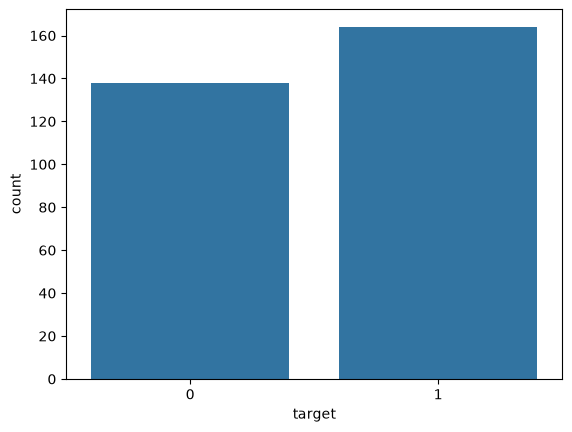

In [39]:
#balancing class
print(df["target"].value_counts())
sns.countplot(x="target", data=df)
plt.show()

In [40]:
#Standardize Data
X = df.drop(columns="target")
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

cont = ["age", "trestbps", "chol", "thalach", "oldpeak"]
scaler = StandardScaler()
X_train[cont] = scaler.fit_transform(X_train[cont])
X_test[cont] = scaler.transform(X_test[cont])

In [41]:
#Resampling's effect on performance
X_smote, y_smote = SMOTE(random_state=42).fit_resample(X_train, y_train)

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)
pred = model.predict(X_test)
print("No resampling - Accuracy:", round(accuracy_score(y_test, pred), 3), "F1:", round(f1_score(y_test, pred), 3))

model.fit(X_smote, y_smote)
pred = model.predict(X_test)
print("SMOTE         - Accuracy:", round(accuracy_score(y_test, pred), 3), "F1:", round(f1_score(y_test, pred), 3))

No resampling - Accuracy: 0.82 F1: 0.841
SMOTE         - Accuracy: 0.82 F1: 0.841


##### Feature Engineering

In [42]:
#Define models used 
models = {"Logistic Regression": LogisticRegression(max_iter=1000),
          "Naive Bayes": GaussianNB(),
          "XGBoost": XGBClassifier(eval_metric="logloss")}

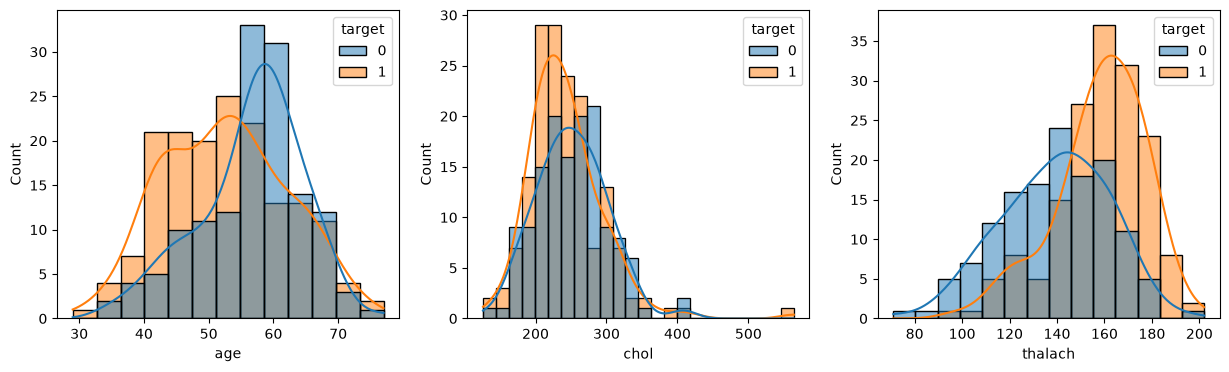

In [43]:
#show distributions in data
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["age", "chol", "thalach"]):
    sns.histplot(data=df, x=col, hue="target", kde=True, ax=ax)
plt.show()

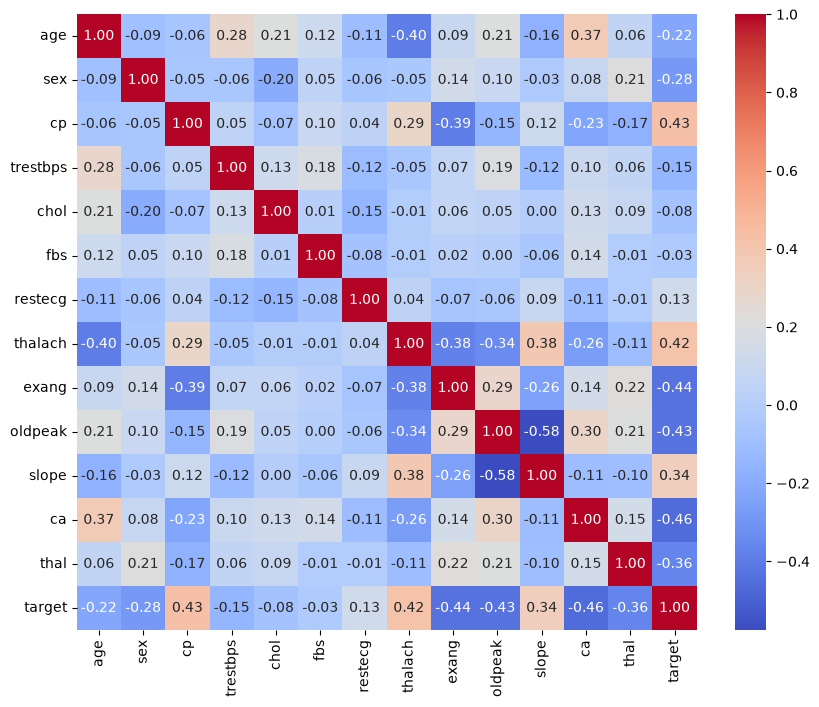

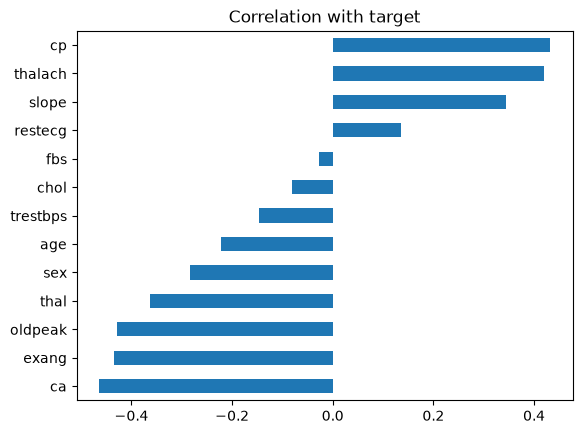

In [44]:
#highlight relationship with outcome
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

df.corr()["target"].drop("target").sort_values().plot(kind="barh")
plt.title("Correlation with target")
plt.show()

In [45]:
# New features
df2 = df.copy()
df2["age_group"] = pd.cut(df2["age"], bins=[0, 45, 55, 65, 120], labels=["under45", "45_54", "55_64", "65plus"])
df2["chol_high"] = (df2["chol"] >= 240).astype(int)

# One-hot encoding for the categorical columns
df2 = pd.get_dummies(df2, columns=["cp", "restecg", "slope", "thal", "age_group"], drop_first=True, dtype=int)

# Polynomial features
poly = PolynomialFeatures(degree=2, include_bias=False)
poly_cols = pd.DataFrame(poly.fit_transform(df2[cont]), columns=poly.get_feature_names_out(cont), index=df2.index)
poly_cols = poly_cols.drop(columns=cont)
df_poly = pd.concat([df2, poly_cols], axis=1)
df_poly.shape

(302, 38)

In [46]:
#feature selectyion based on correlation
corr = df_poly.corr()["target"].abs()
keep = corr[corr > 0.1].index.drop("target")
df_sel = df_poly[list(keep) + ["target"]]
df_sel.shape

(302, 32)

In [47]:
#plotting effects of feasture sets on performance 
def prepare(data):
    X = data.drop(columns="target")
    y = data["target"]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    sc = StandardScaler()
    return sc.fit_transform(X_tr), sc.transform(X_te), y_tr, y_te

sets = {"Original": df, "Engineered": df2, "Engineered + polynomial": df_poly, "Selected": df_sel}

rows = []
for set_name, data in sets.items():
    X_tr, X_te, y_tr, y_te = prepare(data)
    row = {"Feature set": set_name, "n_features": X_tr.shape[1]}
    for name, model in models.items():
        row[name] = cross_val_score(model, X_tr, y_tr, cv=5).mean()
    rows.append(row)

pd.DataFrame(rows).round(3)

,Feature set,n_features,Logistic Regression,Naive Bayes,XGBoost
0,Original,13,0.838,0.843,0.793
1,Engineered,22,0.842,0.822,0.805
2,Engineered + polynomial,37,0.826,0.809,0.789
3,Selected,31,0.830,0.805,0.780


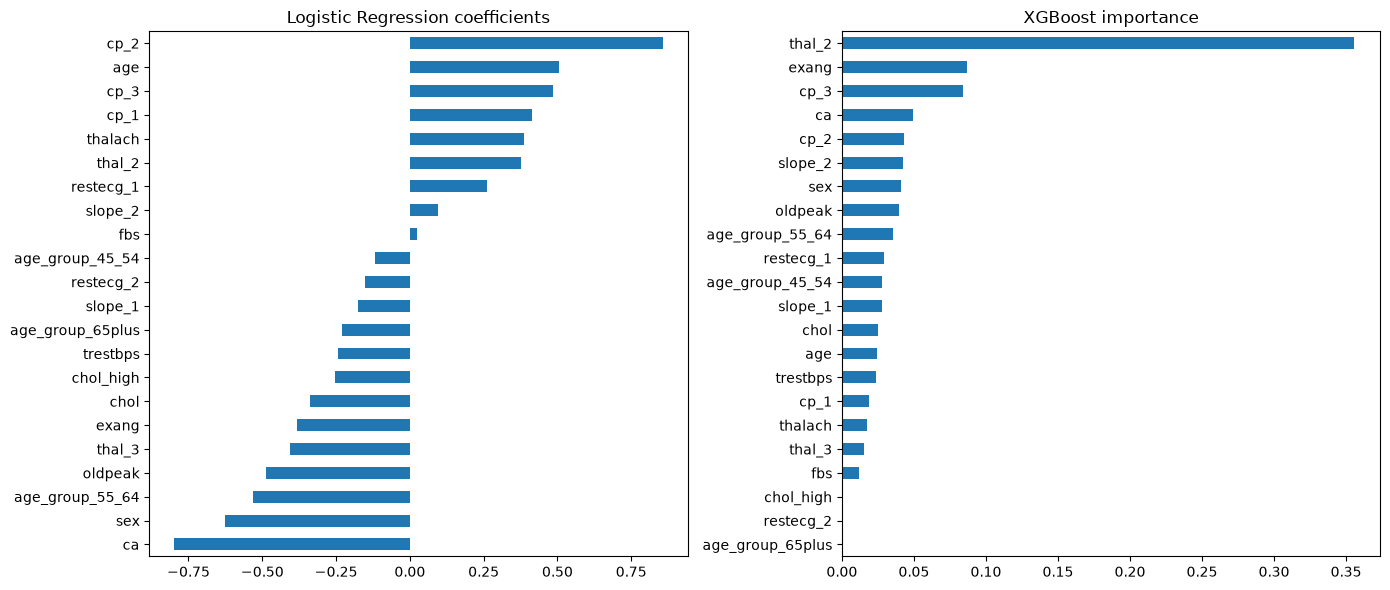

In [48]:
#highlight importance of certain features
#higher importance has a larger addition to predictions
X_tr, X_te, y_tr, y_te = prepare(df2)
names = df2.drop(columns="target").columns

lr = LogisticRegression(max_iter=1000).fit(X_tr, y_tr)
xgb = XGBClassifier(eval_metric="logloss").fit(X_tr, y_tr)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
pd.Series(lr.coef_[0], index=names).sort_values().plot(kind="barh", ax=axes[0], title="Logistic Regression coefficients")
pd.Series(xgb.feature_importances_, index=names).sort_values().plot(kind="barh", ax=axes[1], title="XGBoost importance")
plt.tight_layout()
plt.show()

#### Model Training

##### Model 1: Logistic Regression

In [49]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train) #using train functions from task 1

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

##### Model 2: Gaussian Naive Bayes

In [50]:
#building Gaussian Naive Bayes model using train function from task 1
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[110.,131.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.46,0.54]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.004e-09
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['age','sex','cp',...,'slope','ca','thal']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 13)","[[ 0.23, 0.81, 0.42,..., 1.15, 1.11, 2.59], [-0.19, 0.58, 1.37,..., 1.61, 0.29, 2.15]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 13)","[[0.75,0.15,0.7 ,...,0.32,1.04,0.42], [1.13,0.24,0.84,...,0.34,0.42,0.18]]"


##### Model 3: XGBoost

In [51]:
#building XGBoost model using train function in task 1
xgb_model = XGBClassifier(eval_metric="logloss")
xgb_model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [52]:
#comparing models performance based on test set
fitted_models = {"Logistic Regression": log_reg, "Naive Bayes": nb_model, "XGBoost": xgb_model}

rows = []
for name, m in fitted_models.items():
    pred = m.predict(X_test)
    rows.append([name, accuracy_score(y_test, pred), f1_score(y_test, pred)])

pd.DataFrame(rows, columns=["Model", "Accuracy", "F1"]).round(3)

,Model,Accuracy,F1
0,Logistic Regression,0.820,0.841
1,Naive Bayes,0.836,0.853
2,XGBoost,0.754,0.789


#### Model Evaluation

In [ ]:
#evaluation metrics for each model
rows = []
for name, m in fitted_models.items():
    pred = m.predict(X_test)
    proba = m.predict_proba(X_test)[:, 1]
    rows.append([name, accuracy_score(y_test, pred), precision_score(y_test, pred),
                 recall_score(y_test, pred), f1_score(y_test, pred), roc_auc_score(y_test, proba)])

pd.DataFrame(rows, columns=["Model", "Accuracy", "Precision", "Recall", "F1", "AUC"]).round(3)

,Model,Accuracy,Precision,Recall,F1,AUC
0,Logistic Regression,0.820,0.806,0.879,0.841,0.903
1,Naive Bayes,0.836,0.829,0.879,0.853,0.892
2,XGBoost,0.754,0.737,0.848,0.789,0.866


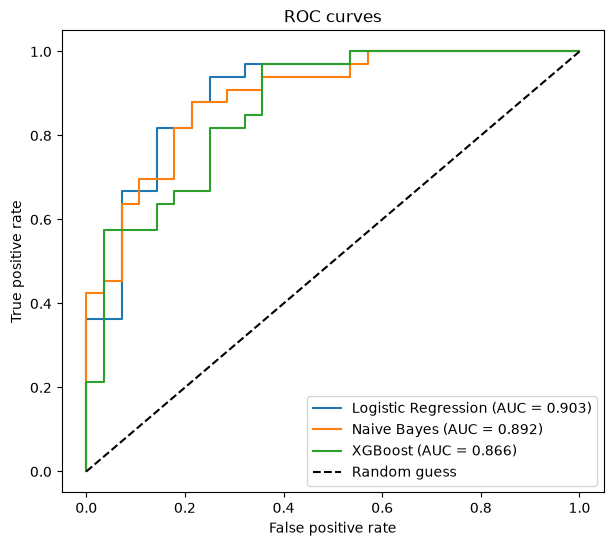

In [ ]:
#plotting ROC curves
plt.figure(figsize=(7, 6))
for name, m in fitted_models.items():
    proba = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves")
plt.legend()
plt.show()

Logistic Regression and Naive Bayes perform the best of the 3, nearly identical, whereas XGBoost is slightly behind the other two. 